In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
from pathlib import Path

from bioio import BioImage

# data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261007 Repeat/Experiment-152.czi")
channels = ["PRRT", "A1", "PSD", "RIM"]
data_path = Path(
    "/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat/Experiment-358.czi"
)
image = BioImage(data_path)
data = image.xarray_dask_data.assign_coords({"C": channels})

In [ ]:
import napari

v = napari.Viewer()
v.add_image(image.data, channel_axis=1, name=channels)

# 2. Drift correction

In [4]:
from prrt_clustering import correct_z_drift

shift, stabilized = correct_z_drift(data)

In [ ]:
import matplotlib.pyplot as plt

plt.plot(shift.reset_index()["Z"], shift["DX [um]"])
plt.plot(shift.reset_index()["Z"], shift["DY [um]"])
plt.legend(["X", "Y"])
plt.xlabel("Z [um]")
plt.ylabel("shift [um]")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

n = 500
a = data[0, 2, :, :n, :n].max(axis=1)
b = stabilized[0, 2, :, :n, :n].max(axis=1)
plt.subplot(311)
a.plot(add_colorbar=False, cmap="gray")
plt.subplot(312)
b.plot(add_colorbar=False, cmap="gray")
plt.subplot(313)
plt.imshow(np.stack([a, b, a], axis=2), aspect=4)
plt.suptitle("Z drift correction")
plt.tight_layout()


In [ ]:
# import napari
# v = napari.Viewer()
# v.add_image(image.data, channel_axis=1)
# v.add_image(stabilized.data[0,0,:,:100,:100], channel_axis=1)

## 3. Spot detection

- Detect spots in all channels

(<Figure size 2000x2000 with 4 Axes>,
 {'A1': <Axes: title={'center': 'A1'}>,
  'PRRT': <Axes: title={'center': 'PRRT'}>,
  'PSD': <Axes: title={'center': 'PSD'}>,
  'RIM': <Axes: title={'center': 'RIM'}>})

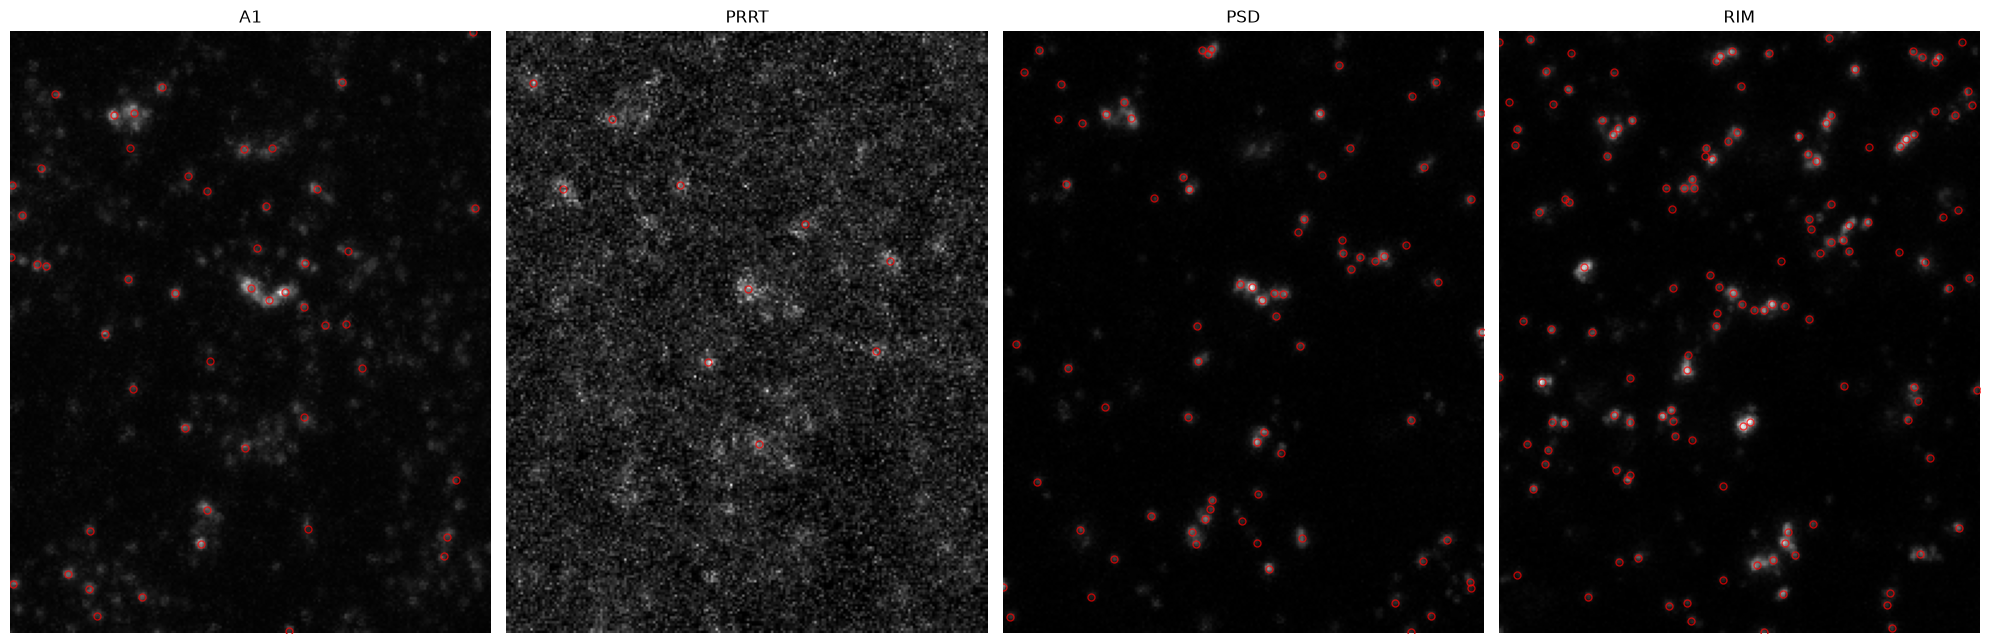

In [5]:
import matplotlib.pyplot as plt
import numpy as np

from prrt_clustering import detect_puncta, plot_data, plot_points

tmp = stabilized[0, :, :, 250:500, 800:1000]
parameters = {
    "PRRT": {"scale_um": 0.4, "specificity": 6},
    "A1": {"scale_um": 0.3, "specificity": 6},
    "PSD": {"scale_um": 0.1, "specificity": 8},
    "RIM": {"scale_um": 0.1, "specificity": 6},
}

points = detect_puncta(tmp, parameters)

fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp, split=True, fig=fig)
plot_points(points, ms=10, split=True, axes_dict=axes)


In [ ]:
import napari

v = napari.Viewer(ndisplay=3)
# v.add_image(image.data, channel_axis=1)
vx = np.array([(tmp[a][1].values - tmp[a][0].values) for a in ["Z", "Y", "X"]])
o = np.array([tmp[a][0].values for a in ["Z", "Y", "X"]])
# v.add_image(tmp,scale=vx,translate=o, channel_axis=0,name=channels)
fcol = {"PRRT": "magenta", "A1": "red", "PSD": "green", "RIM": "yellow"}
for n, pts in points.groupby("C"):
    v.add_image(tmp.sel(C=n), scale=vx, translate=o, name=n, colormap=fcol[n])
    v.add_points(pts[["Z", "Y", "X"]], size=0.5, name=n, face_color=fcol[n])

## 3. Clustering of RIM and PSD channels
Cluster points to identify potential synapses.

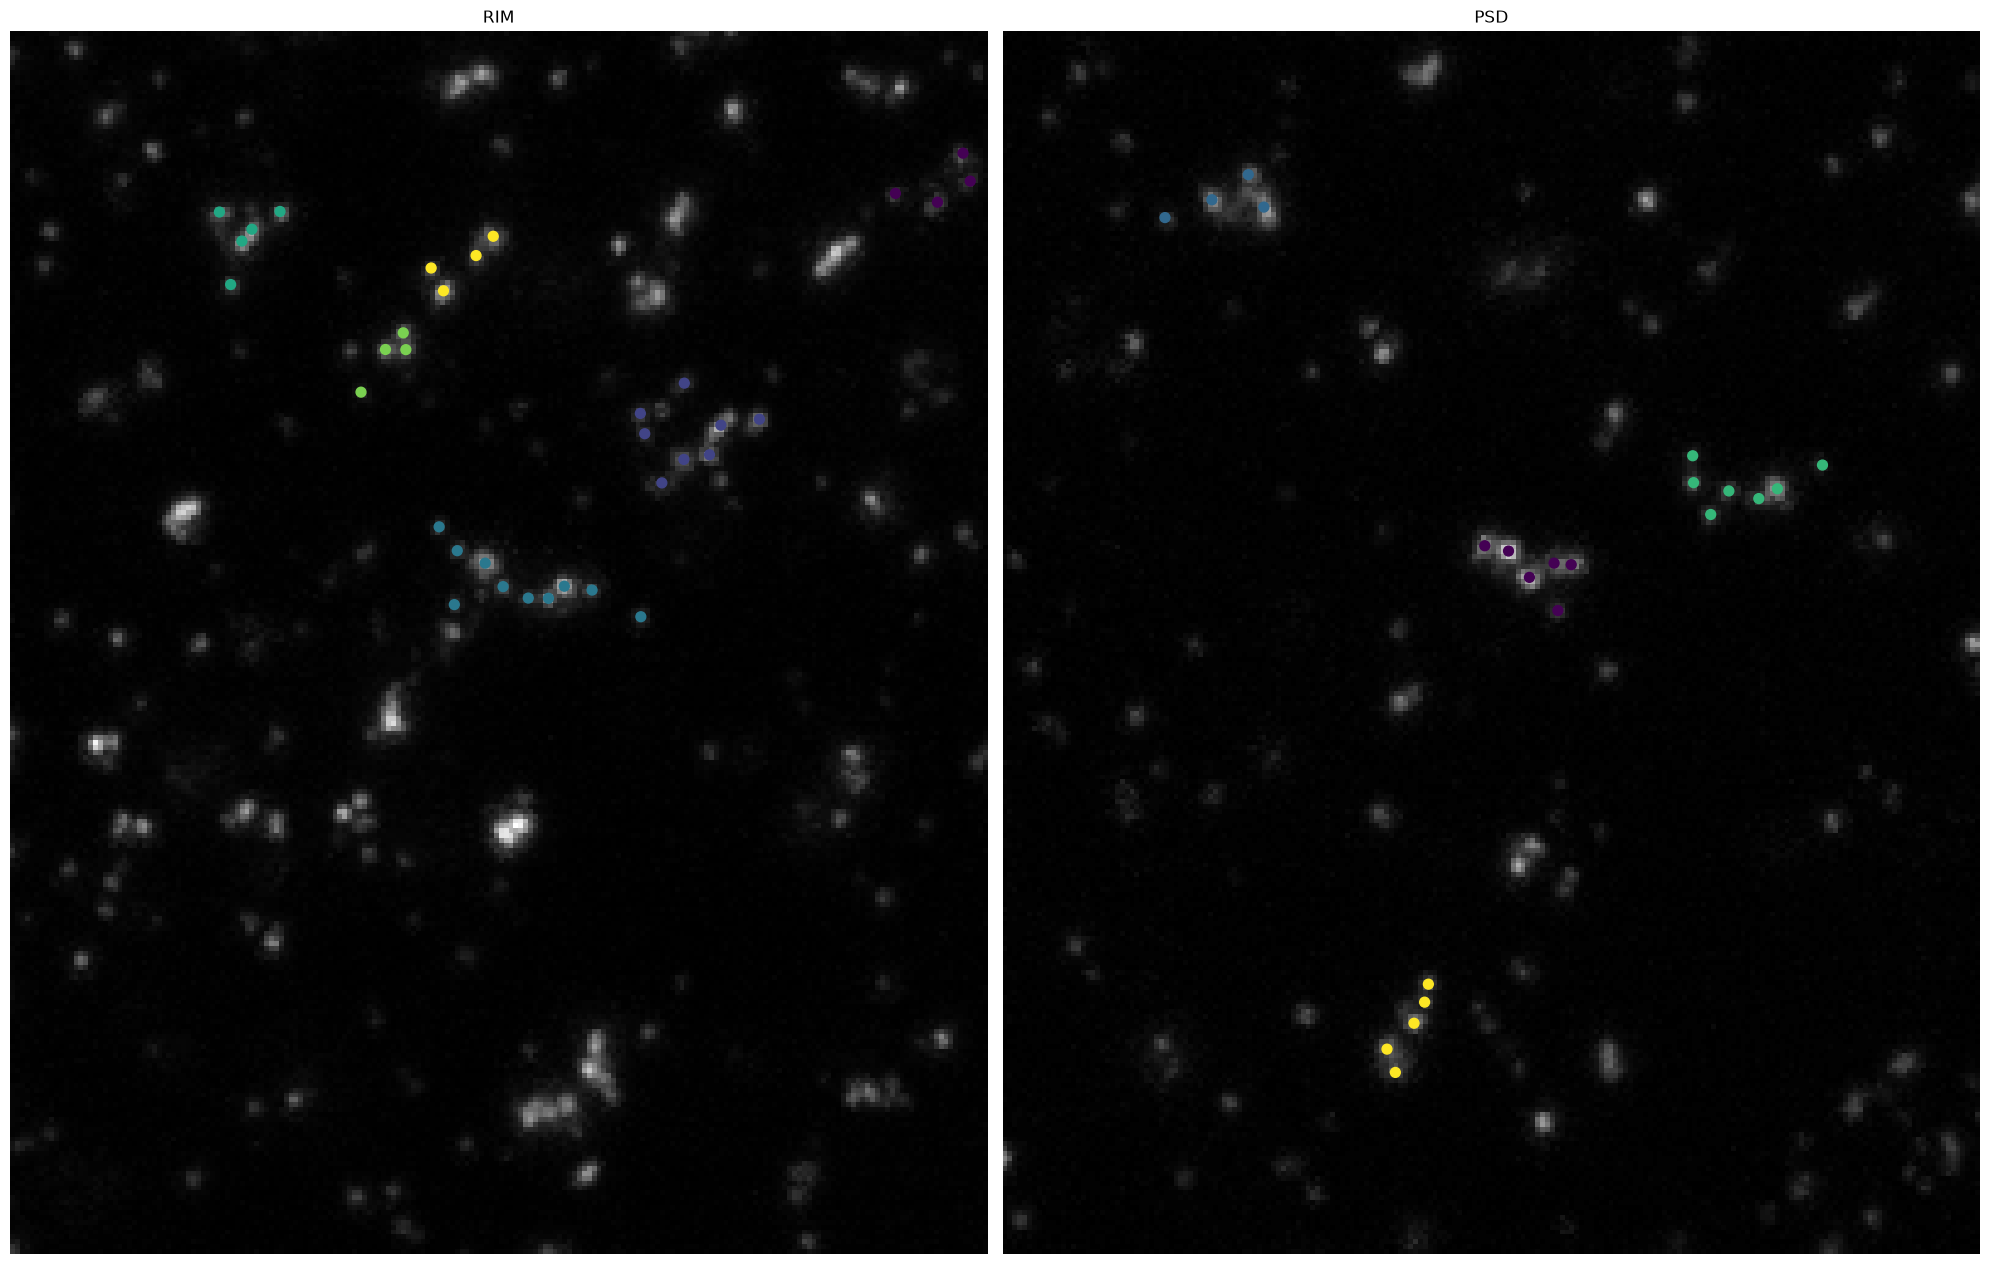

In [ ]:
from prrt_clustering import cluster_dbscan

points, clusters = cluster_dbscan(points, eps=1.5, min_samples=4)

fig = plt.figure(figsize=(10, 10))
fig, axes = plot_data(tmp.sel(C=["RIM","PSD"]), split=True, fig=fig)

fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp, split=True, fig=fig)
for n,g in points[(points["synapse_id"]>=0&(points["C"]).isin(["RIM","PSD"]))].groupby("C"):
    axes[n].scatter(g['X'],g['Y'],c=g['synapse_id'],s=50)

x = points[(points["cluster_id"]>=0)&(points["C"]=="RIM")]
axes["RIM"].scatter(x['X'],x['Y'],c=x['cluster_id'],s=50)
x = points[(points["cluster_id"]>=0)&(points["C"]=="PSD")]
axes["PSD"].scatter(x['X'],x['Y'],c=x['cluster_id'],s=50)

## 4. Pre-post synpatic cluster association
Identify synapses as pair of cluster

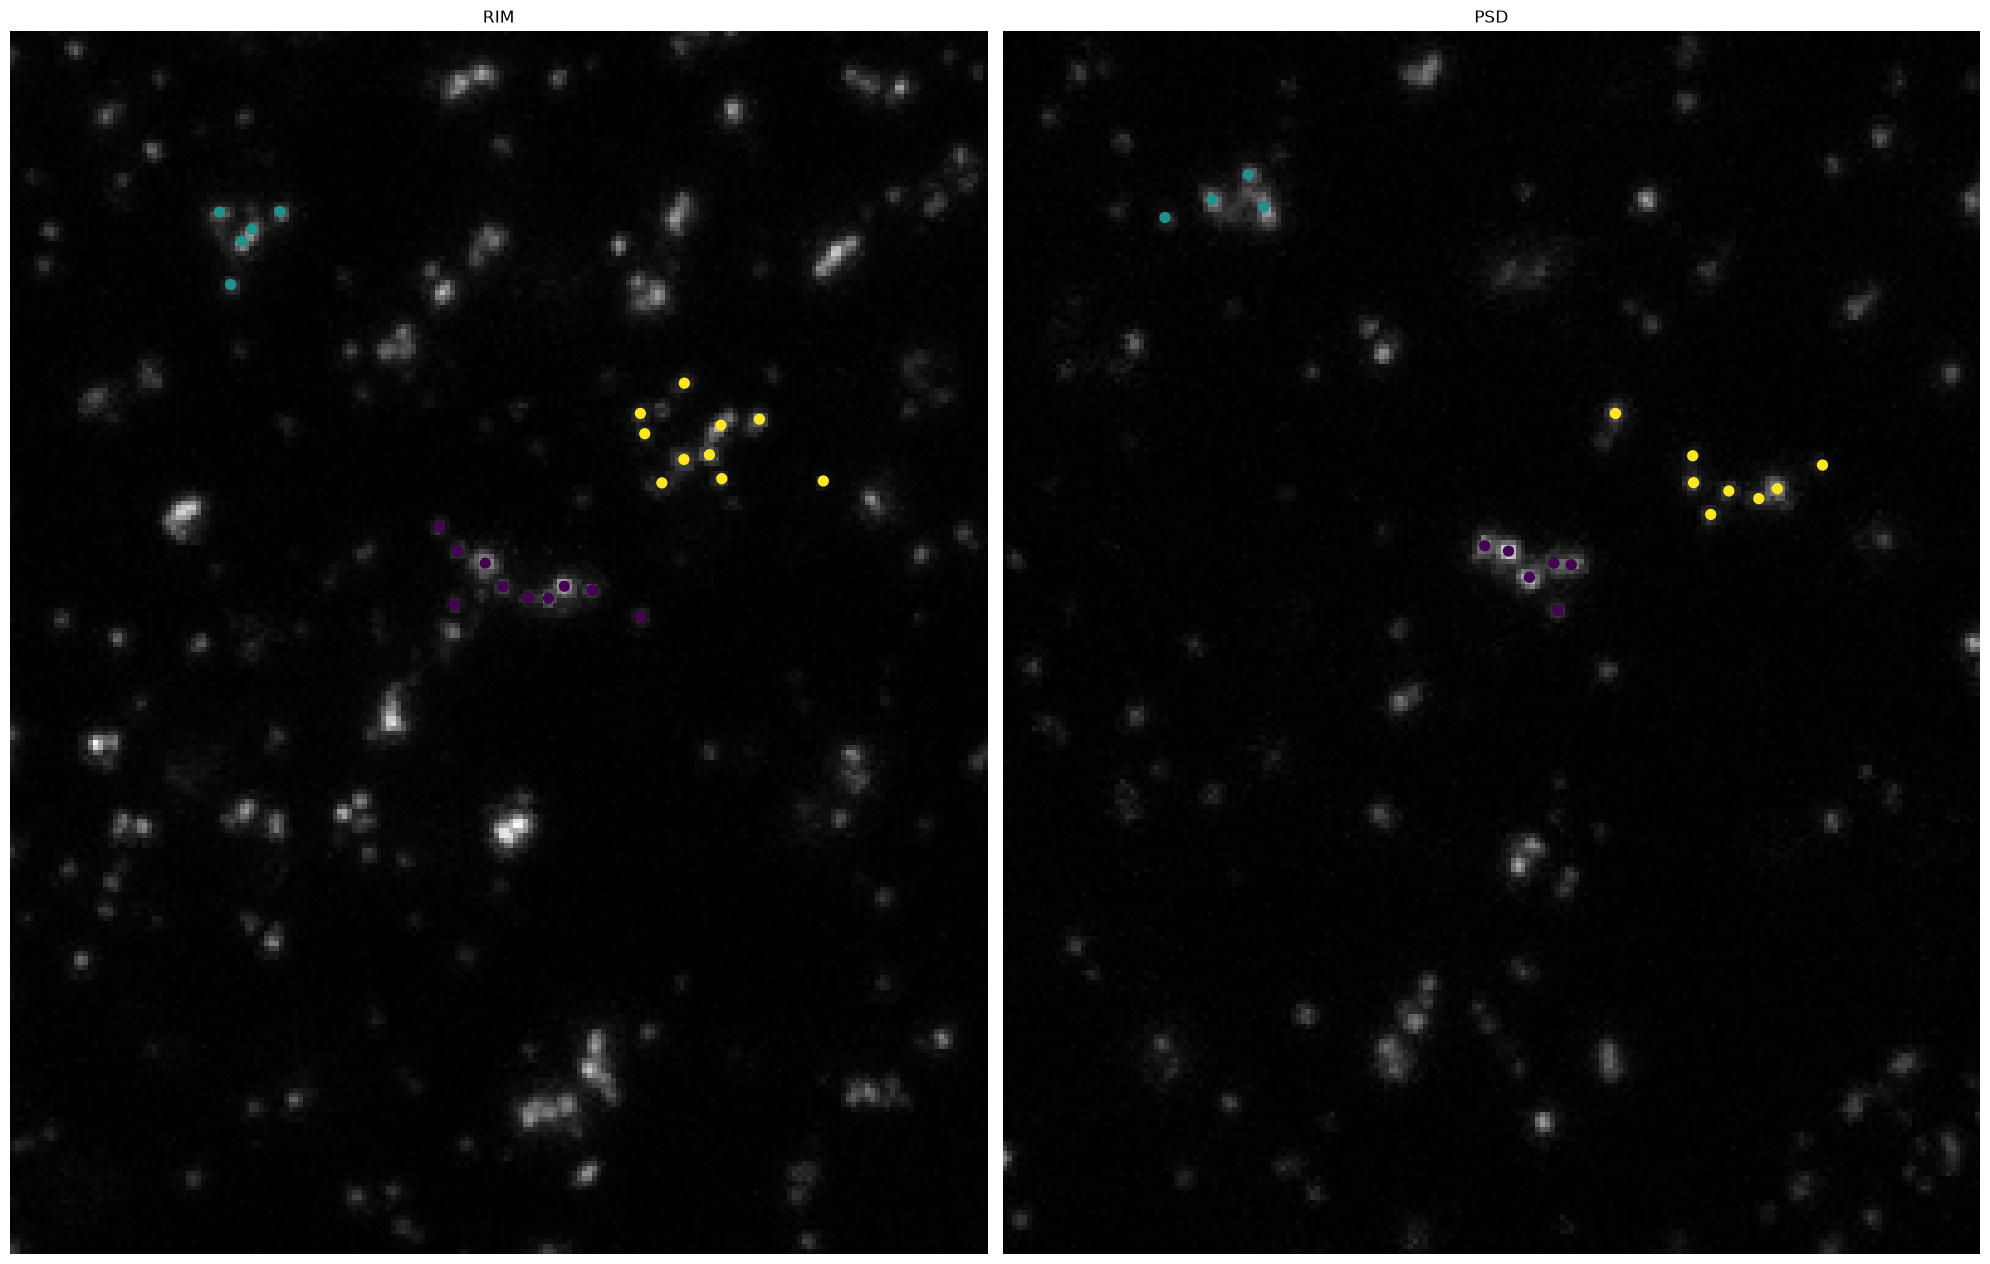

In [ ]:
from prrt_clustering import pair_cluster

points, synapses = pair_cluster(points, ["PSD", "RIM"], distance=1)

fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp, split=True, fig=fig)
for n,g in points[points["synapse_id"]>=0].groupby("C"):
    axes[n].scatter(g['X'],g['Y'],c=g['synapse_id'],s=50)


## 5. Identify pair of A1-PRRT

Identify pair of A1-PRRT puncta


In [8]:
from prrt_clustering import pair_puncta

points, pairs = pair_puncta(points,["A1","PRRT"],distance=0.5)

## 6. Synapse profiling

For each synapse, associate the puncate in all channel


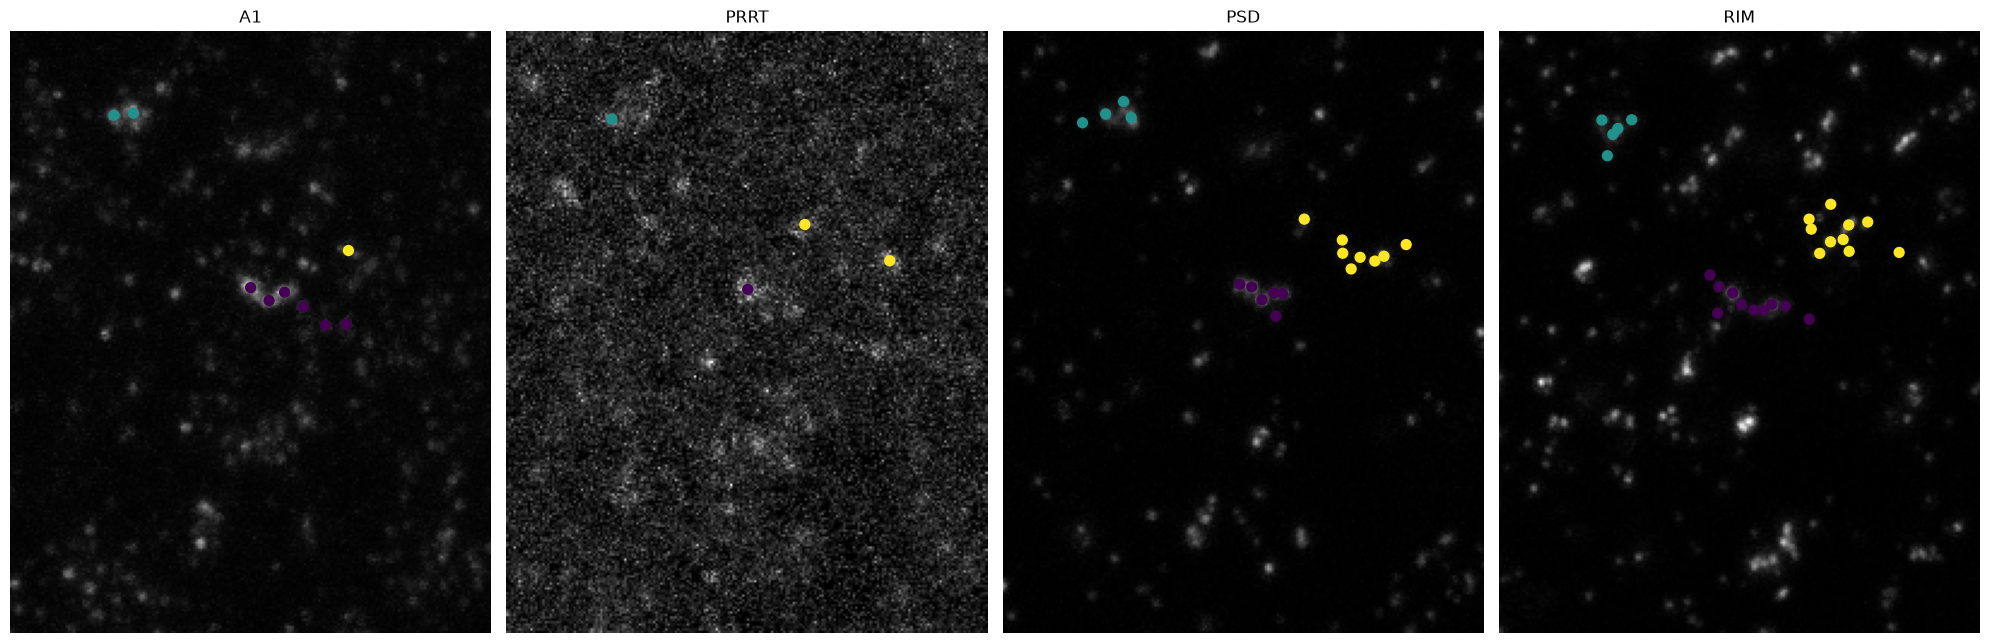

In [41]:
from prrt_clustering.clustering import associate_to_paired_cluster, compute_distances

points = associate_to_paired_cluster(points, 0.25)
points = compute_distances(points)

fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp, split=True, fig=fig)
for n,g in points[points["synapse_id"]>=0].groupby("C"):
    axes[n].scatter(g['X'],g['Y'],c=g['synapse_id'],s=50)


In [27]:
import pandas as pd

records = []

for n,g in points[points["synapse_id"]>=0].groupby("synapse_id"):
    records.append({
        "synapse":int(n),
        "Number of RIM puncta": len(g[g["C"]=="RIM"]),
        "Number of PSD puncta": len(g[g["C"]=="PSD"]),
        "Number of A1 puncta": len(g[g["C"]=="A1"]),
        "Number of PRRT puncta": len(g[g["C"]=="PRRT"]),
        "Number of A1-PRRT complex": len(g[g["pair_id"]>=0]),
        "Mean distance PRRT:PSD": g[g["C"]=="PRRT"]["distance to PSD"].mean().item(),
        "Mean distance PRRT:RIM": g[g["C"]=="PRRT"]["distance to RIM"].mean().item(),
        "Mean distance A1:PSD": g[g["C"]=="A1"]["distance to PSD"].mean().item(),
        "Mean distance A1:RIM": g[g["C"]=="A1"]["distance to RIM"].mean().item(),
        "Mean distance PRRT:A1": g[g["C"]=="PRRT"]["distance to A1"].mean().item(),
    })
pd.DataFrame.from_records(records)

,synapse,Number of RIM puncta,Number of PSD puncta,Number of A1 puncta,Number of PRRT puncta,Number of A1-PRRT complex,Mean distance PRRT:PSD,Mean distance PRRT:RIM,Mean distance A1:PSD,Mean distance A1:RIM,Mean distance PRRT:A1
0,0,10,6,5,1,2,0.360677,0.730130,0.707941,0.585695,0.491086
1,1,5,4,2,1,2,0.594734,1.127094,0.229195,0.663601,0.412324
2,2,10,8,1,2,0,0.438176,0.810115,0.439013,0.521227,1.833327


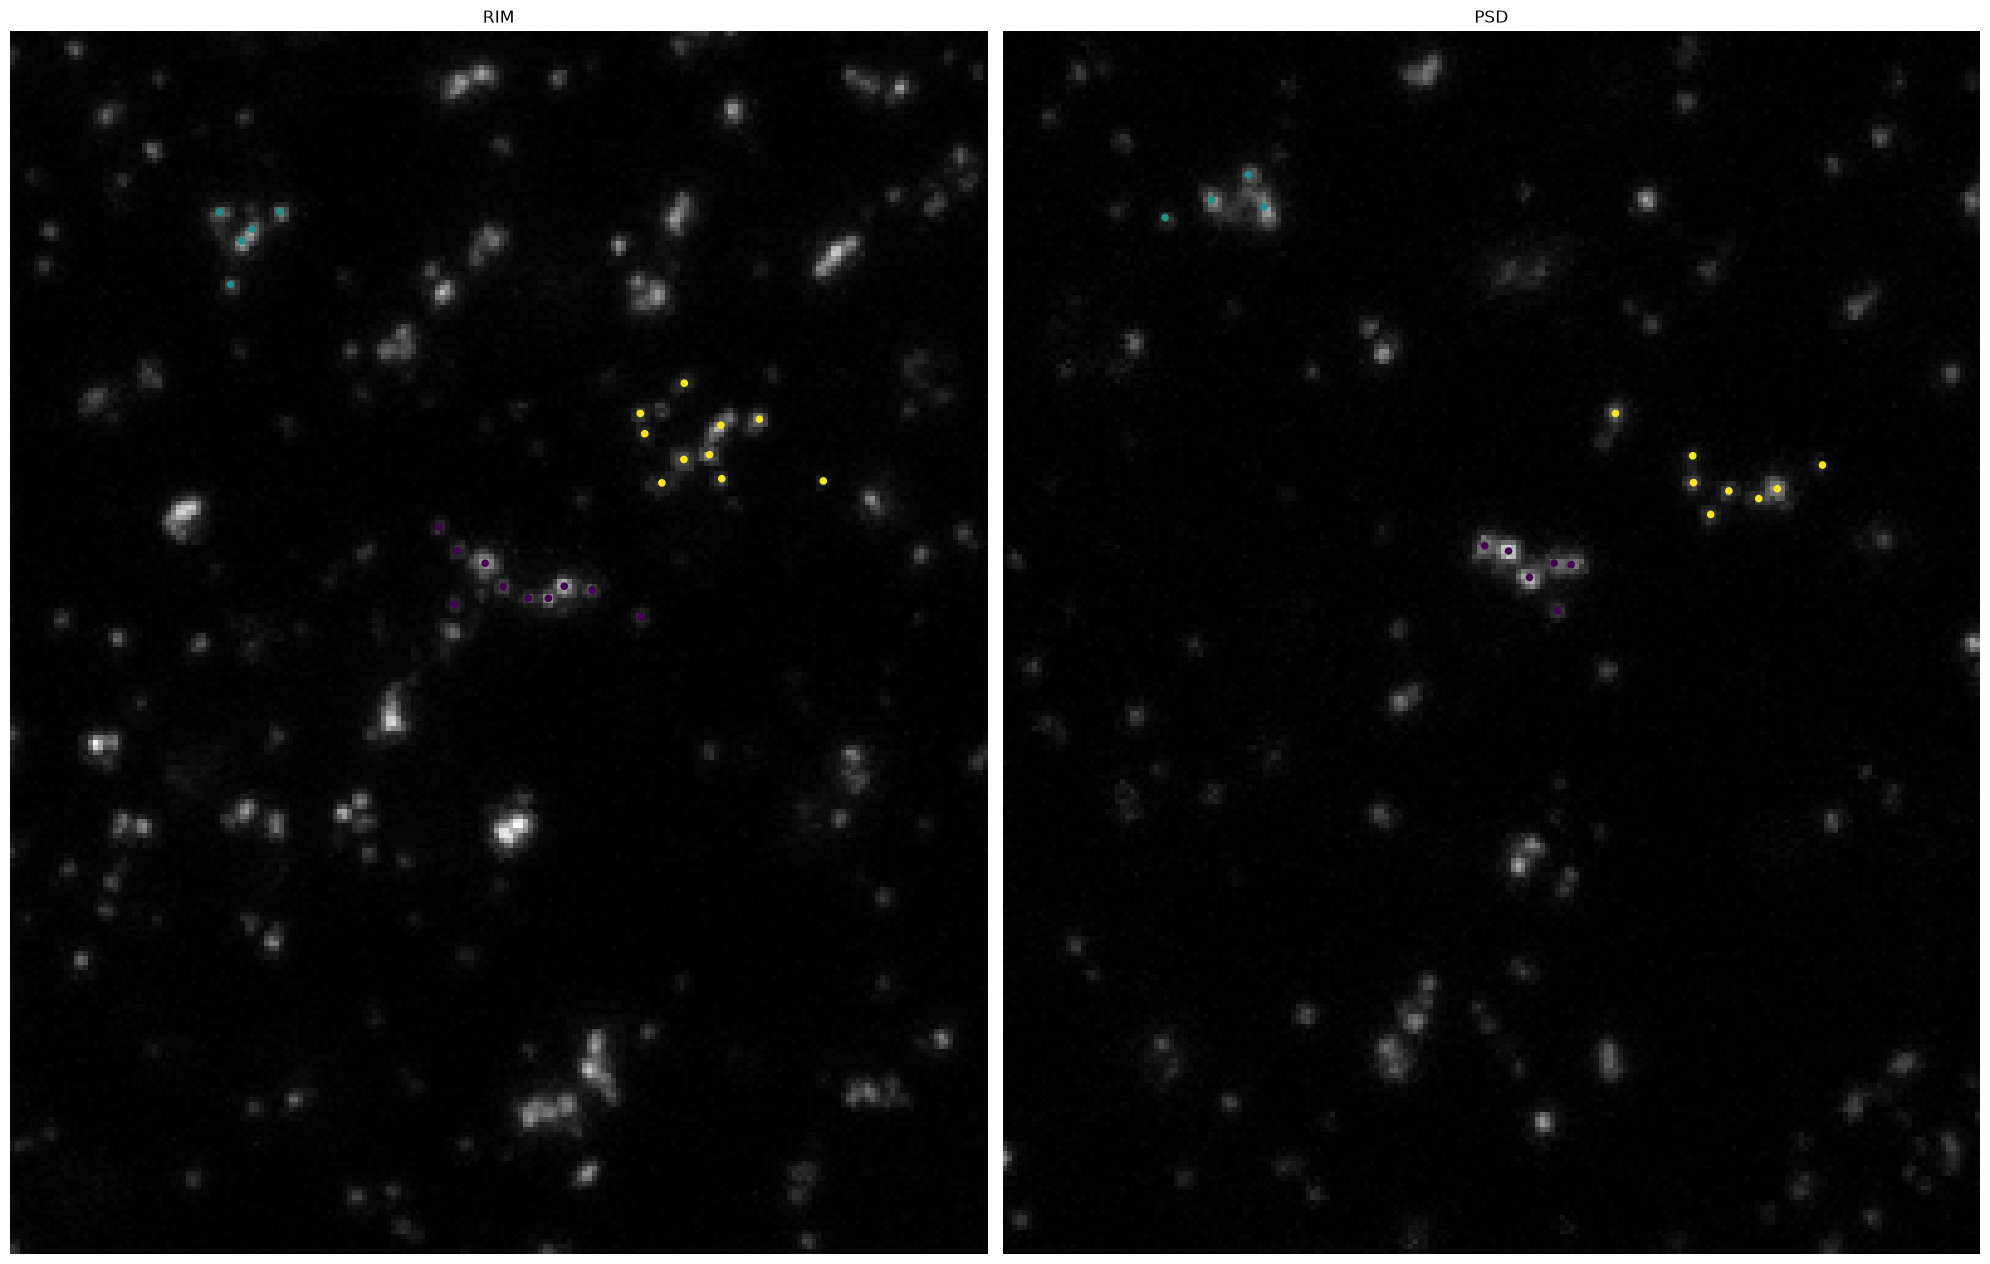

In [33]:
fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp.sel(C=["RIM","PSD"]), split=True, fig=fig)
x = points[(points["synapse_id"]>=0)&(points["C"]=="RIM")]
axes["RIM"].scatter(x['X'],x['Y'],c=x['synapse_id'],s=20)
x = points[(points["synapse_id"]>=0)&(points["C"]=="PSD")]
axes["PSD"].scatter(x['X'],x['Y'],c=x['synapse_id'],s=20)


In [ ]:
from prrt_clustering import find_synapses, plot_clusters
import pandas as pd

spoints, clusters, synapses = find_synapses(points, eps=1.5, min_samples=2, distance=1.)
# points = spoints[spoints["noise"]==False]
fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp.sel(C=["RIM","PSD"]), split=True, fig=fig)
# fig, axes = plot_points(clusters, split=True, axes_dict=axes)
# plot_points(spoints, ms=0.5, split=True, axes_dict=axes)
x = spoints[(spoints["synapse"]>=0)&(spoints["C"]=="RIM")]
axes["RIM"].scatter(x['X'],x['Y'],c=x['synapse'],s=2)
x = spoints[(spoints["synapse"]>=0)&(spoints["C"]=="PSD")]
axes["PSD"].scatter(x['X'],x['Y'],c=x['synapse'],s=2)


In [ ]:
from prrt_clustering.clustering import quantification

df = quantification(spoints, 0.5)
df

In [ ]:
# PRRT1 at GluA1-containing synapse
num_synapses = len(df)
num_prrt = len(points[points["C"]=="PRRT"])
num_a1 = len(points[points["C"]=="A1"])
num_psd = len(points[points["C"]=="PSD"])
num_rim = len(points[points["C"]=="RIM"])
num_a1_synapses = (df["A1"] > 0).sum()
num_psd_clusters = spoints[spoints["C"]=="PSD"]["cluster"].nunique()-1
num_rim_clusters = spoints[spoints["C"]=="RIM"]["cluster"].nunique()-1
num_a1_prrt_synapses = ((df["PRRT"] > 0) & ( df["A1"] > 0)).sum()
{
    "Number of PRRT puncta": num_prrt,
    "Number of A1 puncta": num_a1,
    "Number of PSD puncta": num_psd,
    "Number of RIM puncta": num_rim,
    "Number of PSD cluster": num_psd_clusters,
    "Number of RIM cluster": num_rim_clusters,
    "Number of synpases (PSD+RIM)": num_synapses,
    "Number of GluA1-containing synapse":int(num_a1_synapses),
    "Fraction of PRRT1 at GluA1-containing synapse [%]":float(100.*num_a1_prrt_synapses/num_a1_synapses),
 }
